In [1]:
import tables as tb
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pyvista as pv

In [2]:
with tb.open_file('../out/gate_probe/geometry_probe_4.h5', 'r') as file:
    print(file)
    print(file.root.MC.volume_changes.read())
    # print(file.root.MC.config.read())

../out/gate_probe/geometry_probe_4.h5 (File) ''
Last modif.: '2026-06-30T11:01:02+00:00'
Object Tree: 
/ (RootGroup) ''
/MC (Group) ''
/MC/config (Table(np.int64(52),)zlib(4)) ''
/MC/volume_changes (Table(np.int64(1961944),)) ''

[(40004, b'geantino', b'liquids', b'gate', -13.649626 ,  -6.8969903,  -7.8020372, -13.649626 ,  -6.8969903, 62.9)
 (40004, b'geantino', b'liquids', b'gate', -13.649626 ,  -6.8969903,  -7.8020372, -13.649626 ,  -6.8969903, 62.9)
 (40004, b'geantino', b'liquids', b'gate', -13.649626 ,  -6.8969903,  -7.8020372, -13.649626 ,  -6.8969903, 62.9)
 ...
 (49989, b'geantino', b'liquids', b'gate', -29.571163 , -10.470271 , -26.923933 , -29.571163 , -10.470271 , 62.9)
 (49992, b'geantino', b'liquids', b'gate',  -6.4267306,  20.446548 , -41.527252 ,  -6.4267306,  20.446548 , 62.9)
 (49997, b'geantino', b'liquids', b'gate',  22.28594  , -22.553532 ,  35.949516 ,  22.28594  , -22.553532 , 62.9)]


In [3]:
volume_changes = []
for i in range(12):
    with tb.open_file(f'../out/gate_probe/geometry_probe_{i}.h5', 'r') as file:
        volume_changes.append(file.root.MC.volume_changes.read())

print(np.shape(volume_changes[0]))

(2050919,)


In [4]:
print(volume_changes[0].dtype.names)

('event', 'particle', 'pre_volume', 'post_volume', 'pre_x', 'pre_y', 'pre_z', 'post_x', 'post_y', 'post_z')


In [5]:
x = np.concatenate([volume_changes[i]['post_x'] for i in range(12)])
y = np.concatenate([volume_changes[i]['post_y'] for i in range(12)])
z = np.concatenate([volume_changes[i]['post_z'] for i in range(12)])

/tmp/ipykernel_33061/2101858767.py:47: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show(interactive=False)


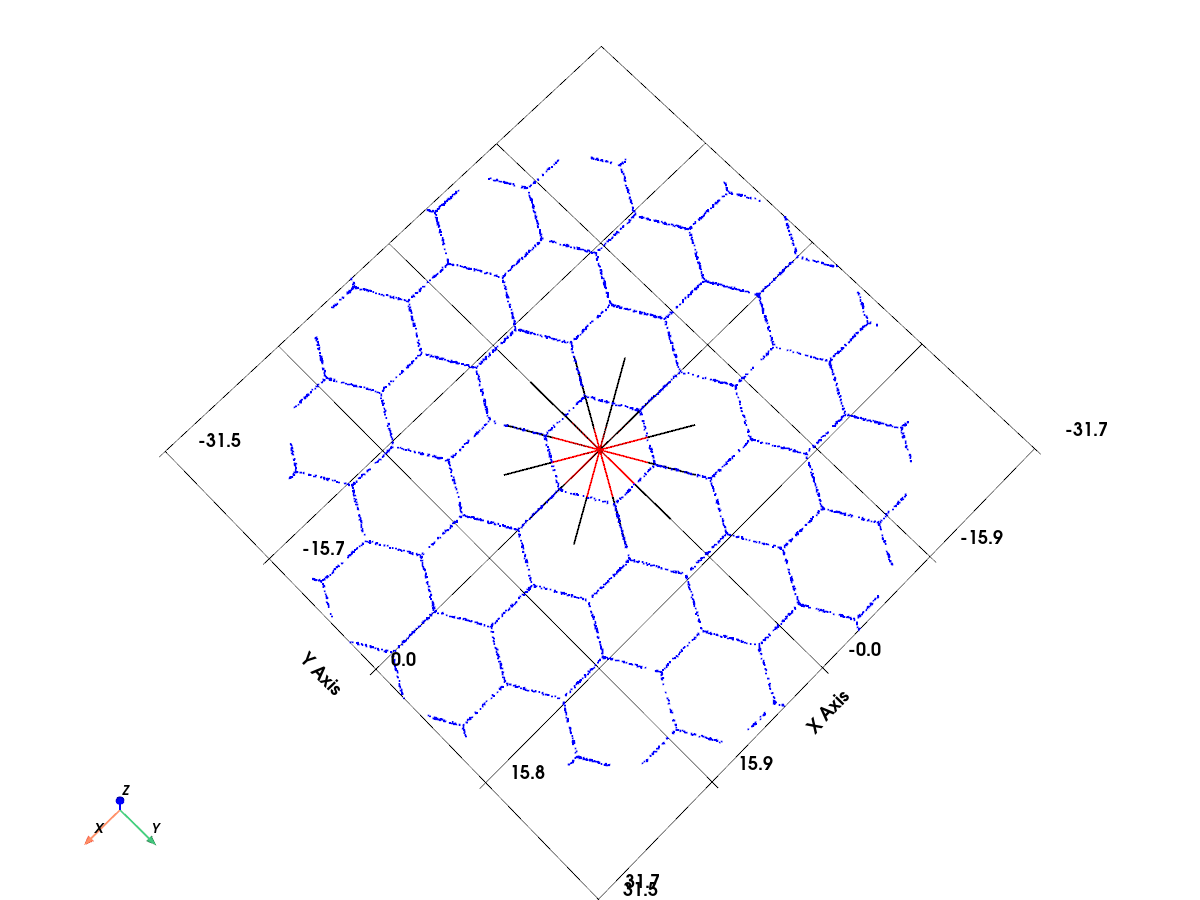

In [6]:
points = np.column_stack((x, y, z))
cloud = pv.PolyData(points)

plotter = pv.Plotter(window_size=(1200, 900))
plotter.set_scale(xscale=1, yscale=1, zscale=5)

plotter.add_points(
    cloud,
    color="blue",
    point_size=2,
    render_points_as_spheres=False
)

# --- LÍNEAS CADA 30 GRADOS EN PLANO XY ---

# radio de las líneas (ajústalo a tu escena)
radius = 10.2#np.max(np.sqrt(x**2 + y**2))

# altura del plano XY (elige z=0 o el valor que prefieras)
z0 = z[0]

for angle_deg in range(0, 360, 30):
    angle = np.deg2rad(angle_deg)

    x_end = radius * np.cos(angle)
    y_end = radius * np.sin(angle)

    line = pv.Line(
        pointa=(0, 0, z0),
        pointb=(x_end, y_end, z0)
    )
    line2 = pv.Line(
        pointa=(0, 0, z0),
        pointb=(x_end/2, y_end/2, z0)
    )

    plotter.add_mesh(line, color="black", line_width=2)
    plotter.add_mesh(line2, color="red", line_width=2)

# --- cámara y extras ---
plotter.camera.azimuth = 0
plotter.camera.elevation = 70

plotter.add_axes()
plotter.show_grid()

plotter.show(interactive=False)

In [ ]:


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(tracks[0], tracks[1], tracks[2], s=2)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()